# Análise exploratória: COVID-19, Brasil.IO

Autor: Marcelo Barbosa de Oliveira Junior. Professor: Alexandre Louzada. Fonte: `caso_full`, versão fixada no manifesto. Dados até 27/03/2022. Execute na raiz do repositório após `python -m src.etl`. A análise é descritiva e não estima causalidade.


## 1. Carga e proveniência
Usamos apenas o painel estadual para totais nacionais e o municipal para a auditoria de repetições.


In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from src.analysis import summarize

root = Path.cwd()
out = root / 'data' / 'processed'
daily = pd.read_csv(out / 'national_daily.csv.gz', parse_dates=['date'])
states = pd.read_csv(out / 'state_latest.csv')
quality = pd.read_csv(out / 'quality_by_state.csv')
manifest = json.loads((out / 'manifest.json').read_text(encoding='utf-8'))
print('SHA-256 do original:', manifest['source_sha256'])
print('Linhas brutas:', manifest['raw_rows'])
print('Dias com 27 UFs:', len(daily), '| UFs na última data:', len(states))
print('Nulos brutos auditados:', manifest['missing_values_by_raw_column'])


SHA-256 do original: dd60678588f09c46e867284887067e0a002a448e846aff3734374bfc19e87dd5
Linhas brutas: 3853648
Dias com 27 UFs: 737 | UFs na última data: 27
Nulos brutos auditados: {'last_available_confirmed': 0, 'new_confirmed': 0, 'last_available_deaths': 0, 'new_deaths': 0, 'estimated_population_2019': 13646, 'estimated_population': 13646, 'is_repeated': 0}


## 2. Distribuição e tendência temporal
As séries são notificações diárias; valores negativos por revisão são mantidos. A média móvel exige sete dias consecutivos.


Primeira e última data: 2020-03-21 2022-03-27
Casos nacionais negativos em dias completos: 1


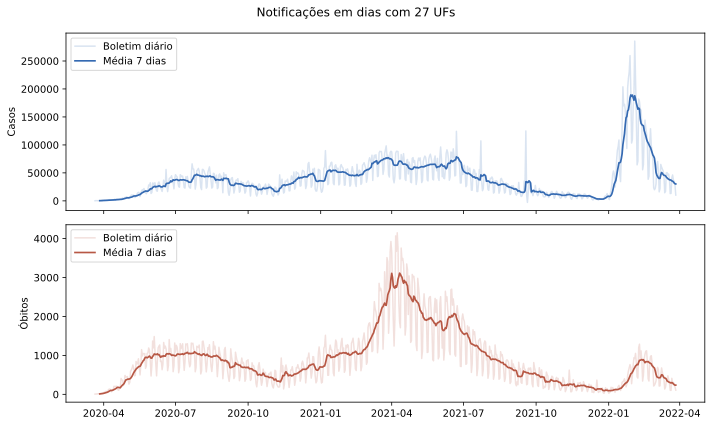

In [2]:
print('Primeira e última data:', daily.date.min().date(), daily.date.max().date())
print('Casos nacionais negativos em dias completos:', int((daily.reported_cases < 0).sum()))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, raw, moving, label, color in [(axes[0], 'reported_cases', 'cases_7d', 'Casos', '#356ab2'),
                                      (axes[1], 'reported_deaths', 'deaths_7d', 'Óbitos', '#b75845')]:
    ax.plot(daily.date, daily[raw], color=color, alpha=.18, label='Boletim diário')
    ax.plot(daily.date, daily[moving], color=color, linewidth=1.7, label='Média 7 dias')
    ax.set_ylabel(label)
    ax.legend(loc='upper left')
fig.suptitle('Notificações em dias com 27 UFs')
fig.tight_layout()


## 3. Variação entre UFs
Incidência por 100 mil moradores na última data, 27/03/2022. O desvio padrão usa `ddof=1`; a correlação de Spearman é exploratória, pois incidência e letalidade por casos compartilham casos confirmados.


Incidência (mín., Q1, mediana, Q3, máx.): 5995.6 11717.7 14805.2 20347.5 25809.4
Média, DP amostral, IQR e CV%: 16106.4 5492.4 8629.8 34.1
Spearman incidência × letalidade por casos: -0.744


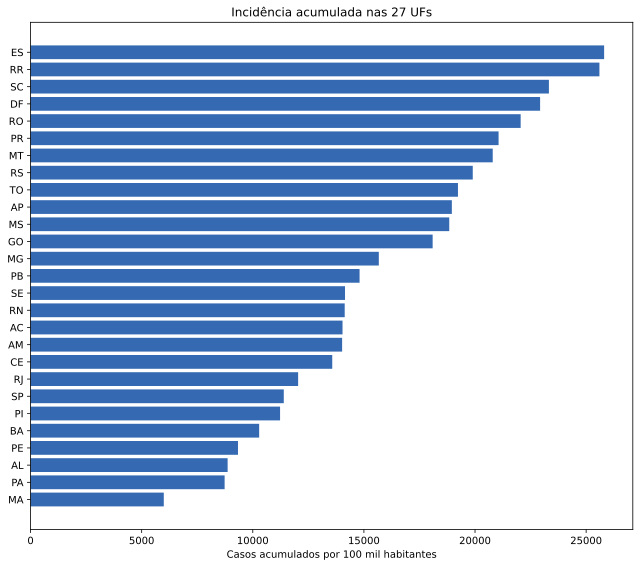

In [3]:
stats = summarize()
print('Incidência (mín., Q1, mediana, Q3, máx.):',
      *(f'{stats["incidence"][key]:.1f}' for key in ('min','q1','median','q3','max')))
print('Média, DP amostral, IQR e CV%:',
      *(f'{stats["incidence"][key]:.1f}' for key in ('mean','std_sample','iqr','cv_pct')))
print('Spearman incidência × letalidade por casos:',
      f'{stats["rank_correlation_incidence_case_fatality"]:.3f}')
ranking = states.sort_values('incidence_100k')
plt.figure(figsize=(9, 8))
plt.barh(ranking.state, ranking.incidence_100k, color='#356ab2')
plt.xlabel('Casos acumulados por 100 mil habitantes')
plt.title('Incidência acumulada nas 27 UFs')
plt.tight_layout()


## 4. Qualidade e picos de notificação
Um pico é uma razão acima de Q3 + 1,5×IQR em 730 dias candidatos; a linha de base é a mediana dos sete dias anteriores consecutivos e deve superar 100 casos. Um pico não implica aumento real de infecções naquele dia.


In [4]:
spikes = pd.read_csv(out / 'reporting_spikes.csv')
print('Linhas municipais:', stats['repeated']['rows'])
print('Repetidas:', stats['repeated']['count'],
      f'({stats["repeated"]["pct"]:.2f}%)')
print('Mediana estadual de repetição:', f'{stats["repeated"]["state_median_pct"]:.2f}%')
print('Dias candidatos / sinalizados:', stats['reporting_spikes']['candidate_days'], '/', len(spikes))
print('Limiar da razão:', f'{stats["reporting_spikes"]["upper_fence_ratio"]:.3f}')
print('Cinco maiores razões de notificação:')
print(spikes[['date','reported_cases','baseline_7d','ratio']].head().to_string(index=False))


Linhas municipais: 3833529
Repetidas: 1015288 (26.48%)
Mediana estadual de repetição: 24.44%
Dias candidatos / sinalizados: 730 / 35
Limiar da razão: 1.962
Cinco maiores razões de notificação:
      date  reported_cases  baseline_7d    ratio
2021-09-18          124878      13762.0 9.074117
2022-01-07           53371      12314.0 4.334172
2022-01-06           46697      12314.0 3.792188
2021-01-07           89769      25039.0 3.585167
2020-03-31            1164        355.0 3.278873


## Interpretação e limites
A heterogeneidade de incidência pode refletir testagem, acesso e critérios de registro, além da circulação do vírus. Linhas municipais repetidas são características de publicação, não novos casos. O último registro da fonte é de março de 2022. Consulte o artigo em `docs/index.html` para métodos, resultados, referências e a discussão completa.
